In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import LabelEncoder

In [3]:
# loading data
df = pd.read_csv('./Mall_Customers.csv')

In [4]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [5]:
df.shape

(200, 5)

In [6]:
df.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='str')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [8]:
df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [9]:
## data preprocessing
le = LabelEncoder()

In [10]:
df['Gender'] = le.fit_transform(df['Gender'])

In [11]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,1,19,15,39
1,2,1,21,15,81
2,3,0,20,16,6
3,4,0,23,16,77
4,5,0,31,17,40


In [12]:
## choosing annual income and spending score
X = df.iloc[:,[3,4]].values

In [20]:
X

array([[ 15,  39],
       [ 15,  81],
       [ 16,   6],
       [ 16,  77],
       [ 17,  40],
       [ 17,  76],
       [ 18,   6],
       [ 18,  94],
       [ 19,   3],
       [ 19,  72],
       [ 19,  14],
       [ 19,  99],
       [ 20,  15],
       [ 20,  77],
       [ 20,  13],
       [ 20,  79],
       [ 21,  35],
       [ 21,  66],
       [ 23,  29],
       [ 23,  98],
       [ 24,  35],
       [ 24,  73],
       [ 25,   5],
       [ 25,  73],
       [ 28,  14],
       [ 28,  82],
       [ 28,  32],
       [ 28,  61],
       [ 29,  31],
       [ 29,  87],
       [ 30,   4],
       [ 30,  73],
       [ 33,   4],
       [ 33,  92],
       [ 33,  14],
       [ 33,  81],
       [ 34,  17],
       [ 34,  73],
       [ 37,  26],
       [ 37,  75],
       [ 38,  35],
       [ 38,  92],
       [ 39,  36],
       [ 39,  61],
       [ 39,  28],
       [ 39,  65],
       [ 40,  55],
       [ 40,  47],
       [ 40,  42],
       [ 40,  42],
       [ 42,  52],
       [ 42,  60],
       [ 43,

In [21]:
##chooching number of cluster

In [22]:
## wcss  ->  within cluster sum of suqure

In [23]:
## finding wcss value for the diffrent number of clusters

In [30]:
wcss = []

for i in range(1,11):
    km = KMeans(n_clusters=i,init='k-means++',random_state=42)
    km.fit(X)
    wcss.append(km.inertia_)

Text(0, 0.5, 'Wcss')

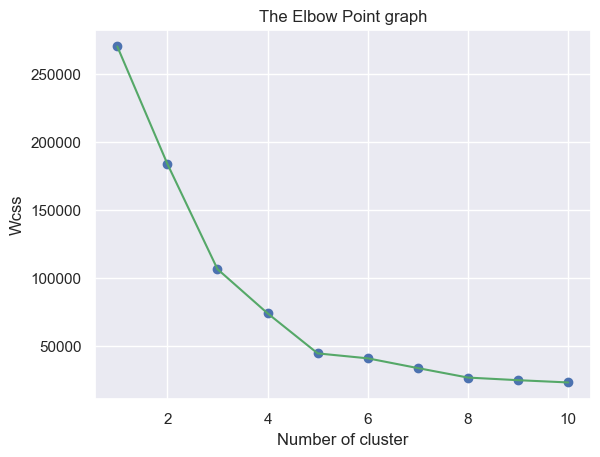

In [45]:
sns.set()
plt.plot(range(1,11),wcss,'o')
plt.plot(range(1,11),wcss,'g')
plt.title('The Elbow Point graph')
plt.xlabel('Number of cluster')
plt.ylabel('Wcss')

In [86]:
## in graph tow elbow show 3 or
## optimum number of cluster is 5
km = KMeans(n_clusters=5,random_state=0,init='k-means++')

## return a lable for each data point based on thire cluster
y = km.fit_predict(X)

## add lable for the all customer
df['lable'] = y

In [87]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),lable
0,1,1,19,15,39,3
1,2,1,21,15,81,4
2,3,0,20,16,6,3
3,4,0,23,16,77,4
4,5,0,31,17,40,3


In [51]:
y

array([3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4,
       3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 0,
       3, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 1, 0, 1, 2, 1, 2, 1,
       0, 1, 2, 1, 2, 1, 2, 1, 2, 1, 0, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1,
       2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1,
       2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1,
       2, 1], dtype=int32)

Text(0, 0.5, 'Spending Score (1-100)')

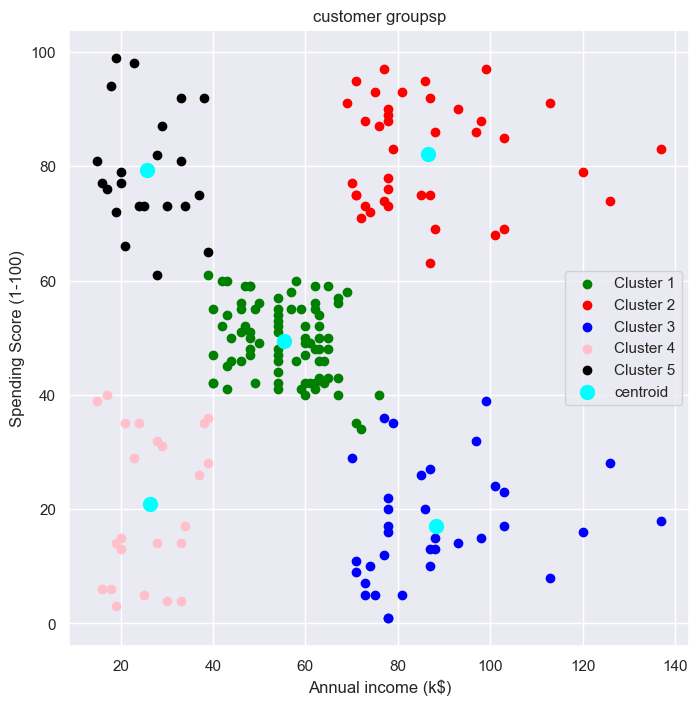

In [85]:
## plot the all clusters

plt.figure(figsize=(8,8))

plt.scatter(X[y==0,0],X[y==0,1],label='Cluster 1',color='green')
plt.scatter(X[y==1,0],X[y==1,1],label='Cluster 2',color='red')
plt.scatter(X[y==2,0],X[y==2,1],label='Cluster 3',color='blue')
plt.scatter(X[y==3,0],X[y==3,1],label='Cluster 4',color='pink')
plt.scatter(X[y==4,0],X[y==4,1],label='Cluster 5',color='black')


## plot the centroids
plt.scatter(km.cluster_centers_[:,0],km.cluster_centers_[:,1],s=100,c='cyan',label='centroid')

plt.legend()
plt.title('customer groupsp')
plt.xlabel('Annual income (k$)')
plt.ylabel('Spending Score (1-100)')

In [ ]:
## more offer for the blue,pink color customer
## gree point customer low offer provides